<a href="https://colab.research.google.com/github/jhonathanrodriguez1/Curso---FDG2026/blob/main/PMD1_Checkpoint_Caso01_Delivery_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PMD1 · Checkpoint de avance técnico (Semana 6)
## Caso 01 · Delivery: entregas a domicilio
**Curso:** Fundamentos de Gestión de Datos · TECSUP 2026-II
**Docente:** Pilar Rocío Sayán Mejía

**Integrantes del equipo (nombres completos):**
- Jhonathan Steven rodriguez Gonzales
> Este cuaderno muestra el **avance** del proyecto. Al final se separa claramente lo **realizado** de lo **pendiente**.

## 1. Problema, objetivo y unidad de análisis

**Contexto:** una empresa de comida a domicilio despacha pedidos desde cinco cocinas. Los clientes reclaman porque el tiempo prometido en la aplicación casi nunca coincide con el tiempo real.

**Pregunta del proyecto:** ¿cuántos minutos adicionales de entrega se asocian a cada kilómetro de distancia y qué perfiles de entrega conviene separar para prometer tiempos más realistas?

**Objetivo del análisis:** integrar y limpiar los registros de entregas para estimar, con una regresión lineal simple, cuánto aumenta el tiempo de entrega (`tiempo_entrega_min`) por cada kilómetro recorrido (`distancia_km`), y así sustentar una promesa de tiempo más realista.

**Unidad de análisis:** cada fila de la hoja **Operaciones** es **una entrega**.

**Origen de la información:** archivo `01_Delivery_PMD1.xlsx` (datos inventados para práctica, en soles), publicado en el repositorio del curso. Los registros los cargan los repartidores desde el celular y el personal de cocina, cada uno con su propio formato; por eso esperamos encontrar problemas de calidad.

## 2. Carga de datos e integración en SQLite

Leemos todas las hojas del Excel directamente desde GitHub y guardamos cada una (menos LEEME) como tabla en una base SQLite.

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

# Ruta del caso en el repositorio del curso
URL = "https://raw.githubusercontent.com/Rociosayan/PMD1_Fundamentos_Gestion_Datos/main/casos_PMD1/01_Delivery/01_Delivery_PMD1.xlsx"

# Cargamos todas las hojas en un diccionario {nombre_hoja: DataFrame}
hojas = pd.read_excel(URL, sheet_name=None)
for nombre, df in hojas.items():
    print(f"{nombre}: {df.shape[0]} filas x {df.shape[1]} columnas")

LEEME: 16 filas x 2 columnas
Operaciones: 466 filas x 9 columnas
Clientes: 120 filas x 4 columnas
Catalogo: 20 filas x 4 columnas
Sedes: 5 filas x 3 columnas


In [2]:
# Nota del archivo (hoja LEEME)
if "LEEME" in hojas:
    display(hojas["LEEME"])

,PMD1 — caso sintetico,01 Delivery
0,Origen,Datos inventados para practica; no son observa...
1,Unidad operativa,Una fila de Operaciones representa entrega
2,Tablas,"Operaciones, Clientes, Catalogo, Sedes"
3,Relaciones,Usar los identificadores compartidos; no hay t...
4,Calidad,"Hay fechas con formatos distintos, nulos, fila..."
5,Regresion,Se puede plantear una pregunta con una sola va...
6,K-Means,"Definir unidad de agrupacion, variables y esca..."
7,Uso,Datos de estudiantes. No incluye resultados ni...
8,Semilla generadora,20261012; casos generados de forma reproducible
9,Moneda,Soles peruanos (S/); todos los datos son sinté...


In [3]:
# Creamos la base SQLite y guardamos cada hoja como tabla
conn = sqlite3.connect("caso_pmd1.db")
for nombre, df in hojas.items():
    if nombre != "LEEME":
        df.to_sql(nombre.lower(), conn, if_exists="replace", index=False)

# Comprobamos qué tablas quedaron en la base
pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn)

,name
0,operaciones
1,clientes
2,catalogo
3,sedes


In [4]:
# Conteo de filas por tabla (comprobación de la carga)
for t in ["operaciones", "clientes", "catalogo", "sedes"]:
    n = pd.read_sql_query(f"SELECT COUNT(*) AS filas FROM {t}", conn)["filas"][0]
    print(f"{t}: {n} filas")

operaciones: 466 filas
clientes: 120 filas
catalogo: 20 filas
sedes: 5 filas


In [5]:
# Columnas de cada tabla
for t in ["operaciones", "clientes", "catalogo", "sedes"]:
    cols = pd.read_sql_query(f"PRAGMA table_info({t})", conn)["name"].tolist()
    print(t, "->", cols)

operaciones -> ['id_operacion', 'id_cliente', 'id_catalogo', 'id_sede', 'fecha', 'distancia_km', 'items_pedido', 'carga_operativa_pct', 'tiempo_entrega_min']
clientes -> ['id_cliente', 'nombre_cliente', 'ciudad', 'antiguedad_meses']
catalogo -> ['id_catalogo', 'nombre_item', 'nivel', 'precio_referencia_soles']
sedes -> ['id_sede', 'nombre_sede', 'zona']


### 2.1 Claves y relaciones (modelo relacional)

- **operaciones**: PK `id_operacion`; FK `id_cliente` → clientes, `id_catalogo` → catalogo, `id_sede` → sedes.
- **clientes**: PK `id_cliente` (nombre, ciudad, antigüedad en meses).
- **catalogo**: PK `id_catalogo` (plato, nivel, precio de referencia en soles).
- **sedes**: PK `id_sede` (nombre de la cocina y zona).

Relación: **muchas entregas → un cliente / un plato / una sede** (1 a N).

A continuación verificamos que las PK sean únicas y que las FK de operaciones existan en su tabla de origen.

In [6]:
# ¿Las claves primarias son únicas y no nulas?
pks = {"operaciones": "id_operacion", "clientes": "id_cliente", "catalogo": "id_catalogo", "sedes": "id_sede"}
for t, pk in pks.items():
    r = pd.read_sql_query(
        f"SELECT COUNT(*) AS filas, COUNT(DISTINCT {pk}) AS distintos, "
        f"SUM(CASE WHEN {pk} IS NULL THEN 1 ELSE 0 END) AS nulos FROM {t}", conn)
    print(f"{t}.{pk}: filas={r.filas[0]}, distintos={r.distintos[0]}, nulos={r.nulos[0]}")

operaciones.id_operacion: filas=466, distintos=460, nulos=0
clientes.id_cliente: filas=120, distintos=120, nulos=0
catalogo.id_catalogo: filas=20, distintos=20, nulos=0
sedes.id_sede: filas=5, distintos=5, nulos=0


In [7]:
# Integridad referencial: FK de operaciones que NO existen en la tabla relacionada
fks = [("id_cliente", "clientes"), ("id_catalogo", "catalogo"), ("id_sede", "sedes")]
for fk, tabla in fks:
    q = f"""
    SELECT COUNT(*) AS huerfanos
    FROM operaciones o
    LEFT JOIN {tabla} t ON o.{fk} = t.{fk}
    WHERE t.{fk} IS NULL
    """
    print(f"operaciones.{fk} sin correspondencia en {tabla}:", pd.read_sql_query(q, conn).huerfanos[0])

operaciones.id_cliente sin correspondencia en clientes: 0
operaciones.id_catalogo sin correspondencia en catalogo: 0
operaciones.id_sede sin correspondencia en sedes: 0


### 2.2 Consultas SQL con JOIN

Unimos las cuatro tablas y respondemos preguntas del negocio: tiempo promedio por cocina, por plato y por ciudad del cliente.

In [8]:
# JOIN de las cuatro tablas (primeras filas)
q_join = """
SELECT o.*, c.*, ca.*, s.*
FROM operaciones o
LEFT JOIN clientes  c  ON o.id_cliente  = c.id_cliente
LEFT JOIN catalogo  ca ON o.id_catalogo = ca.id_catalogo
LEFT JOIN sedes     s  ON o.id_sede     = s.id_sede
"""
df_join = pd.read_sql_query(q_join, conn)
# Eliminamos columnas repetidas por el JOIN (las claves aparecen dos veces)
df_join = df_join.loc[:, ~df_join.columns.duplicated()]
print("Filas operaciones:", pd.read_sql_query("SELECT COUNT(*) n FROM operaciones", conn).n[0])
print("Filas después del JOIN:", len(df_join))   # deben coincidir: el LEFT JOIN no debe duplicar entregas
df_join.head()

Filas operaciones: 466
Filas después del JOIN: 466


,id_operacion,id_cliente,id_catalogo,id_sede,fecha,distancia_km,items_pedido,carga_operativa_pct,tiempo_entrega_min,nombre_cliente,ciudad,antiguedad_meses,nombre_item,nivel,precio_referencia_soles,nombre_sede,zona
0,O010001,C01002,P01008,S013,2025-02-05,5.89,4.0,39.3,26.74,Gabriela Chávez Torres,Cusco,9,Ensalada de quinua,intermedio,21.58,Rapidito Delivery San Miguel,Oeste
1,O010002,C01067,P01002,S011,2025-07-20,5.66,3.0,30.5,34.39,Martín Benites Gómez,Lima,4,Pollo a la brasa 1/4,intermedio,35.22,Rapidito Delivery Los Olivos,Norte
2,O010003,C01109,P01013,S015,2025-05-25,2.41,1.0,14.6,18.92,Carlos Ramírez Castillo,Trujillo,1,Ensalada Waldorf,basico,21.38,Rapidito Delivery Surco,Sur
3,O010004,C01086,P01010,S012,2025-09-14,5.99,4.0,33.9,31.02,Diego Condori Gutiérrez,Huancayo,4,Pizza pepperoni familiar,especial,47.51,Rapidito Delivery Cercado de Lima,Centro
4,O010005,C01071,P01020,S011,2025-09-11,9.41,7.0,58.4,66.40,Andrés Reyes Paredes,Huancayo,1,Ensalada fresca de la casa,intermedio,21.74,Rapidito Delivery Los Olivos,Norte


In [9]:
# Tiempo y distancia promedio por cocina (sede)
pd.read_sql_query("""
SELECT o.id_sede, s.*, COUNT(*) AS entregas,
       ROUND(AVG(o.distancia_km), 2)       AS distancia_prom_km,
       ROUND(AVG(o.tiempo_entrega_min), 2) AS tiempo_prom_min
FROM operaciones o
JOIN sedes s ON o.id_sede = s.id_sede
GROUP BY o.id_sede
ORDER BY tiempo_prom_min DESC
""", conn)

,id_sede,id_sede,nombre_sede,zona,entregas,distancia_prom_km,tiempo_prom_min
0,S013,S013,Rapidito Delivery San Miguel,Oeste,86,5.90,31.25
1,S015,S015,Rapidito Delivery Surco,Sur,102,5.43,30.19
2,S011,S011,Rapidito Delivery Los Olivos,Norte,92,5.96,29.56
3,S012,S012,Rapidito Delivery Cercado de Lima,Centro,97,5.52,27.73
4,S014,S014,Rapidito Delivery Comas,Norte,89,5.13,26.98


In [10]:
# Tiempo promedio por plato del catálogo
pd.read_sql_query("""
SELECT o.id_catalogo, ca.*, COUNT(*) AS entregas,
       ROUND(AVG(o.items_pedido), 2)       AS items_prom,
       ROUND(AVG(o.tiempo_entrega_min), 2) AS tiempo_prom_min
FROM operaciones o
JOIN catalogo ca ON o.id_catalogo = ca.id_catalogo
GROUP BY o.id_catalogo
ORDER BY tiempo_prom_min DESC
""", conn)

,id_catalogo,id_catalogo,nombre_item,nivel,precio_referencia_soles,entregas,items_prom,tiempo_prom_min
0,P01014,P01014,Alitas BBQ,basico,35.22,25,3.64,37.86
1,P01005,P01005,Maki acevichado,basico,49.45,24,2.88,34.26
2,P01019,P01019,Pizza suprema familiar,especial,48.33,21,3.52,33.03
3,P01011,P01011,Maki furai,basico,50.39,19,3.68,32.32
4,P01018,P01018,Pizza vegetariana mediana,intermedio,48.44,19,2.89,31.16
5,P01013,P01013,Ensalada Waldorf,basico,21.38,34,3.26,29.96
6,P01010,P01010,Pizza pepperoni familiar,especial,47.51,27,2.85,29.34
7,P01015,P01015,Pizza margarita personal,basico,46.92,18,3.61,29.26
8,P01017,P01017,Pollo broaster,basico,35.01,14,3.00,28.74
9,P01001,P01001,Ensalada César,intermedio,21.31,27,3.62,28.61


In [11]:
# VIEW: guardamos el JOIN dentro de la base como tabla analítica reutilizable (LEFT JOIN: no perdemos entregas)
conn.execute("DROP VIEW IF EXISTS vw_analitica")
conn.execute("""
CREATE VIEW vw_analitica AS
SELECT o.*, c.ciudad, ca.nivel, s.zona
FROM operaciones o
LEFT JOIN clientes  c  ON o.id_cliente  = c.id_cliente
LEFT JOIN catalogo  ca ON o.id_catalogo = ca.id_catalogo
LEFT JOIN sedes     s  ON o.id_sede     = s.id_sede
""")
pd.read_sql_query("SELECT COUNT(*) AS filas_vista FROM vw_analitica", conn)

,filas_vista
0,466


In [12]:
# GROUP BY + HAVING: zonas con más de 50 entregas y su tiempo promedio
pd.read_sql_query("""
SELECT COALESCE(zona, 'SIN SEDE') AS zona, COUNT(*) AS entregas,
       ROUND(AVG(tiempo_entrega_min), 2) AS tiempo_prom_min
FROM vw_analitica
GROUP BY zona
HAVING COUNT(*) > 50
ORDER BY tiempo_prom_min DESC
""", conn)

,zona,entregas,tiempo_prom_min
0,Oeste,86,31.25
1,Sur,102,30.19
2,Norte,181,28.28
3,Centro,97,27.73


In [13]:
# Subconsulta: ciudades cuyo tiempo promedio supera el promedio general
pd.read_sql_query("""
SELECT COALESCE(ciudad, 'SIN CLIENTE') AS ciudad, COUNT(*) AS entregas,
       ROUND(AVG(tiempo_entrega_min), 2) AS tiempo_prom_min
FROM vw_analitica
GROUP BY ciudad
HAVING AVG(tiempo_entrega_min) > (SELECT AVG(tiempo_entrega_min) FROM operaciones)
ORDER BY tiempo_prom_min DESC
""", conn)

,ciudad,entregas,tiempo_prom_min
0,Piura,68,31.95
1,Arequipa,98,30.99


In [14]:
# Entregas de más de 5 km con carga operativa alta (> 70 %)
pd.read_sql_query("""
SELECT COUNT(*) AS entregas_largas_y_cargadas,
       ROUND(AVG(tiempo_entrega_min), 2) AS tiempo_prom_min
FROM operaciones
WHERE distancia_km > 5 AND carga_operativa_pct > 70
""", conn)

,entregas_largas_y_cargadas,tiempo_prom_min
0,21,41.84


**Interpretación (SQL):**
- Se cargaron 466 entregas, 120 clientes, 20 platos y 5 cocinas. El LEFT JOIN y la vista conservan las 466 entregas: la integración no duplica ni pierde filas.
- `id_operacion` tiene 466 filas pero solo 460 valores distintos: hay **6 entregas duplicadas**, que se tratan en la limpieza.
- No hay claves huérfanas: todas las FK de operaciones existen en clientes, catálogo y sedes.
- Las cocinas de la zona Oeste (San Miguel, 31.25 min) y Sur (Surco, 30.19 min) son las más lentas; Centro es la más rápida (27.73 min). Piura y Arequipa superan el tiempo promedio general.
- Las 21 entregas de más de 5 km con carga mayor a 70 % tardan en promedio 41.84 min, bastante más que el promedio (29.13 min): distancia y carga se suman.

## 3. Análisis exploratorio (EDA)

In [15]:
ops = hojas["Operaciones"].copy()
print("Dimensiones de Operaciones:", ops.shape)
ops.info()

Dimensiones de Operaciones: (466, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466 entries, 0 to 465
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_operacion         466 non-null    object 
 1   id_cliente           466 non-null    object 
 2   id_catalogo          466 non-null    object 
 3   id_sede              466 non-null    object 
 4   fecha                466 non-null    object 
 5   distancia_km         462 non-null    float64
 6   items_pedido         461 non-null    float64
 7   carga_operativa_pct  466 non-null    float64
 8   tiempo_entrega_min   463 non-null    float64
dtypes: float64(4), object(5)
memory usage: 32.9+ KB


In [16]:
ops.head(10)

,id_operacion,id_cliente,id_catalogo,id_sede,fecha,distancia_km,items_pedido,carga_operativa_pct,tiempo_entrega_min
0,O010001,C01002,P01008,S013,2025-02-05,5.89,4.0,39.3,26.74
1,O010002,C01067,P01002,S011,2025-07-20,5.66,3.0,30.5,34.39
2,O010003,C01109,P01013,S015,2025-05-25,2.41,1.0,14.6,18.92
3,O010004,C01086,P01010,S012,2025-09-14,5.99,4.0,33.9,31.02
4,O010005,C01071,P01020,S011,2025-09-11,9.41,7.0,58.4,66.40
5,O010006,C01028,P01014,S012,2025-05-26,10.26,4.0,46.9,49.53
6,O010007,C01022,P01002,S011,2025-03-09,3.48,2.0,5.3,22.00
7,O010008,C01011,P01002,S015,2025-12-01,2.90,1.0,21.3,20.22
8,O010009,C01048,P01020,S012,2025-05-15,1.11,2.0,1.0,15.46
9,O010010,C01076,P01013,S012,2025-12-06,2.43,1.0,11.3,28.75


In [17]:
# Resumen de las variables numéricas
num_vars = ["distancia_km", "items_pedido", "carga_operativa_pct", "tiempo_entrega_min"]
# Convertimos a número (si vienen como texto con coma decimal, también)
for c in num_vars:
    ops[c] = pd.to_numeric(ops[c].astype(str).str.replace(",", ".").str.strip()
                           .replace({"nan": np.nan, "": np.nan, "None": np.nan}), errors="coerce")
ops[num_vars].describe().round(2)

,distancia_km,items_pedido,carga_operativa_pct,tiempo_entrega_min
count,462.00,461.00,466.00,463.00
mean,5.58,3.17,33.71,29.13
std,3.11,1.83,21.33,13.38
min,1.11,1.00,1.00,12.68
25%,2.57,1.00,15.05,18.76
50%,5.42,3.00,33.50,25.48
75%,8.66,5.00,49.50,36.23
max,11.89,9.00,90.10,90.88


In [18]:
# Variables categóricas: frecuencias
for c in ["id_sede", "id_catalogo"]:
    print(ops[c].value_counts(dropna=False), "\n")

id_sede
S015    102
S012     97
S011     92
S014     89
S013     86
Name: count, dtype: int64 

id_catalogo
P01013    34
P01012    31
P01008    29
P01010    27
P01001    27
P01009    27
P01004    27
P01007    26
P01014    25
P01002    24
P01005    24
P01006    24
P01019    21
P01016    20
P01020    19
P01018    19
P01011    19
P01015    18
P01017    14
P01003    11
Name: count, dtype: int64 



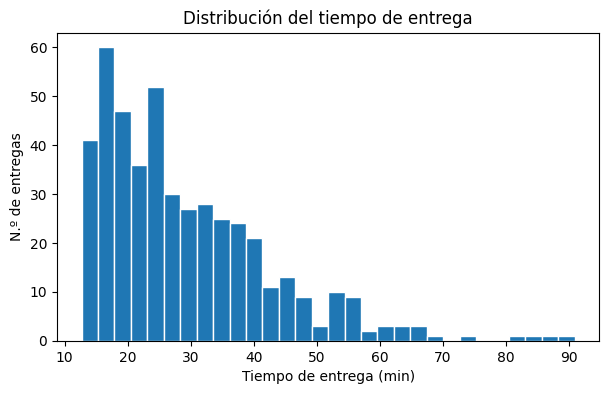

In [19]:
# Gráfico 1: distribución del tiempo de entrega
plt.figure(figsize=(7,4))
plt.hist(ops["tiempo_entrega_min"].dropna(), bins=30, edgecolor="white")
plt.title("Distribución del tiempo de entrega")
plt.xlabel("Tiempo de entrega (min)"); plt.ylabel("N.º de entregas")
plt.show()

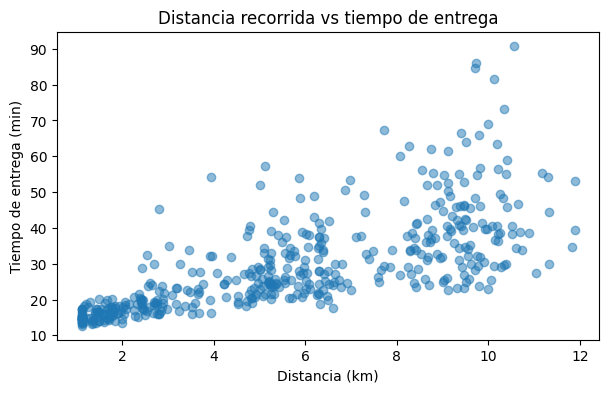

Correlación distancia-tiempo: 0.724


In [20]:
# Gráfico 2: distancia vs tiempo (relación que modelaremos)
plt.figure(figsize=(7,4))
plt.scatter(ops["distancia_km"], ops["tiempo_entrega_min"], alpha=0.5)
plt.title("Distancia recorrida vs tiempo de entrega")
plt.xlabel("Distancia (km)"); plt.ylabel("Tiempo de entrega (min)")
plt.show()
print("Correlación distancia-tiempo:", round(ops[["distancia_km","tiempo_entrega_min"]].corr().iloc[0,1], 3))

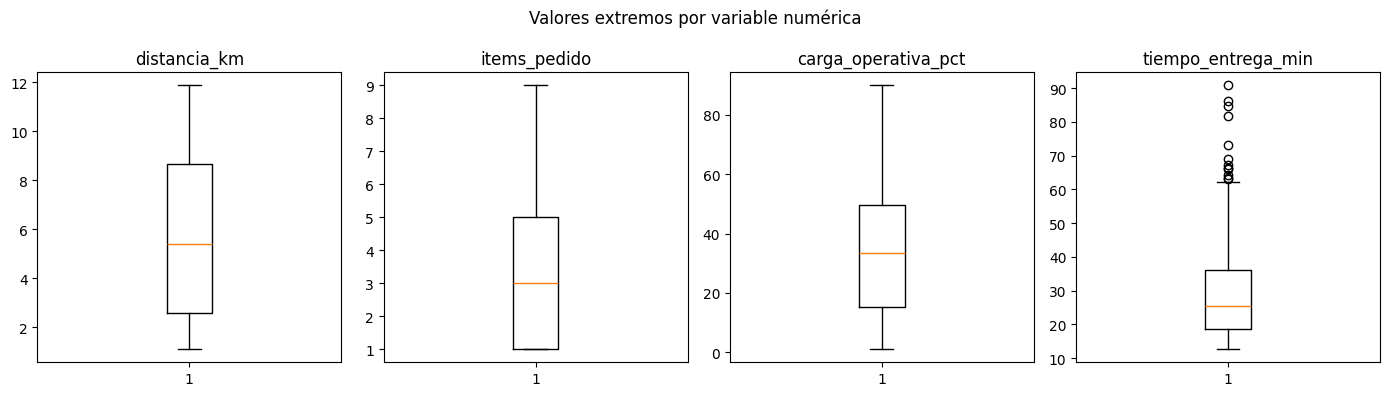

In [21]:
# Gráfico 3: diagramas de caja para detectar valores extremos
fig, axes = plt.subplots(1, 4, figsize=(14,4))
for ax, c in zip(axes, num_vars):
    ax.boxplot(ops[c].dropna())
    ax.set_title(c)
plt.suptitle("Valores extremos por variable numérica")
plt.tight_layout(); plt.show()

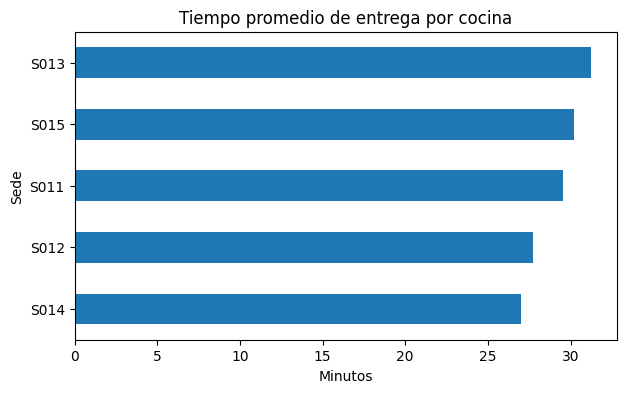

In [22]:
# Gráfico 4: tiempo promedio por sede
ops.groupby("id_sede")["tiempo_entrega_min"].mean().sort_values().plot(kind="barh", figsize=(7,4))
plt.title("Tiempo promedio de entrega por cocina")
plt.xlabel("Minutos"); plt.ylabel("Sede")
plt.show()

**Interpretación (EDA):**
- Operaciones tiene 466 filas y 9 columnas: 4 claves y la fecha como texto, y 4 variables numéricas.
- El tiempo de entrega promedio es 29.13 min (mediana 25.48 min). La media es mayor que la mediana, así que hay una cola de entregas lentas.
- La distancia va de 1.11 a más de 10 km, con un promedio de 5.58 km.
- El diagrama de dispersión muestra una relación **positiva y fuerte** entre distancia y tiempo (correlación = **0.724**). Esto justifica usar `distancia_km` como predictora.
- Los diagramas de caja muestran 12 tiempos atípicos (regla IQR). No hay valores imposibles (negativos o carga fuera de 0–100 %).
- Las cocinas tienen tiempos promedio distintos: la sede también influye y es un límite del modelo simple.

## 4. Avance de limpieza

Cuantificamos cada problema **antes** de tratarlo.

In [23]:
raw = hojas["Operaciones"].copy()
n_inicial = len(raw)
print("Filas iniciales:", n_inicial)

# 4.1 Nulos por columna
print("\nNulos por columna:")
print(raw.isna().sum())

Filas iniciales: 466

Nulos por columna:
id_operacion           0
id_cliente             0
id_catalogo            0
id_sede                0
fecha                  0
distancia_km           4
items_pedido           5
carga_operativa_pct    0
tiempo_entrega_min     3
dtype: int64


In [24]:
# 4.2 Duplicados
print("Filas completamente duplicadas:", raw.duplicated().sum())
print("id_operacion repetidos:", raw["id_operacion"].duplicated().sum())

Filas completamente duplicadas: 6
id_operacion repetidos: 6


In [25]:
# 4.3 Espacios de más en los textos
txt_cols = raw.select_dtypes(include="object").columns
for c in txt_cols:
    s = raw[c].dropna().astype(str)
    n = (s != s.str.strip()).sum() + s.str.contains(r"\s{2,}").sum()
    print(f"{c}: {n} valores con espacios de más")

id_operacion: 0 valores con espacios de más
id_cliente: 0 valores con espacios de más
id_catalogo: 0 valores con espacios de más
id_sede: 0 valores con espacios de más
fecha: 0 valores con espacios de más


In [26]:
# 4.4 Fechas escritas de formas distintas
col_fecha = [c for c in raw.columns if "fecha" in c.lower()]
print("Columna(s) de fecha:", col_fecha)
if col_fecha:
    f = raw[col_fecha[0]].astype(str).str.strip()
    # Patrón de cada fecha: cambiamos dígitos por 9 para ver los formatos distintos
    patrones = f.str.replace(r"\d", "9", regex=True)
    print(patrones.value_counts().head(10))

Columna(s) de fecha: ['fecha']
fecha
9999-99-99    446
99/9/9999      11
9/9/9999        6
99/99/9999      3
Name: count, dtype: int64


In [27]:
# 4.5 Valores fuera de rango (imposibles) y atípicos (regla IQR)
tmp = raw.copy()
for c in num_vars:
    tmp[c] = pd.to_numeric(tmp[c].astype(str).str.replace(",", ".").str.strip(), errors="coerce")

print("Distancia <= 0:", (tmp.distancia_km <= 0).sum())
print("Tiempo <= 0:", (tmp.tiempo_entrega_min <= 0).sum())
print("Ítems <= 0:", (tmp.items_pedido <= 0).sum())
print("Carga fuera de 0-100 %:", ((tmp.carga_operativa_pct < 0) | (tmp.carga_operativa_pct > 100)).sum())

def atipicos_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()
for c in num_vars:
    print(f"Atípicos IQR en {c}: {atipicos_iqr(tmp[c].dropna())}")

Distancia <= 0: 0
Tiempo <= 0: 0
Ítems <= 0: 0
Carga fuera de 0-100 %: 0
Atípicos IQR en distancia_km: 0
Atípicos IQR en items_pedido: 0
Atípicos IQR en carga_operativa_pct: 0
Atípicos IQR en tiempo_entrega_min: 12


### 4.6 Tratamientos aplicados (decisiones del equipo)

| Problema | Tratamiento | Justificación |
|---|---|---|
| Espacios de más | `strip()` y un solo espacio | No cambia el dato, solo lo uniforma. |
| Fechas en formatos distintos | Convertir a un formato único (`datetime`) | Permite análisis por fecha; las no convertibles quedan como nulo y se cuentan. |
| Filas duplicadas / `id_operacion` repetido | Eliminar repeticiones, conservar la primera | Una entrega no puede contarse dos veces. |
| Valores imposibles (distancia o tiempo ≤ 0, carga fuera de 0–100) | Convertir a nulo | Son errores de registro, no entregas reales. |
| Nulos en `distancia_km` o `tiempo_entrega_min` | Excluir esas filas | Son las variables del modelo; imputarlas inventaría la relación. |
| Nulos en otras variables numéricas | Imputar con la mediana | Conserva el registro sin distorsionar por extremos. |
| Atípicos IQR válidos | **Conservar** (solo marcar) | Una entrega larga puede ser real; se decide en la entrega final. |

In [28]:
df = raw.copy()

# a) Espacios en textos
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)

# b) Números
for c in num_vars:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", ".").str.strip(), errors="coerce")

# c) Fechas a formato único
if col_fecha:
    cf = col_fecha[0]
    df[cf] = pd.to_datetime(df[cf].astype(str), format="mixed", dayfirst=True, errors="coerce")
    print("Fechas no convertibles:", df[cf].isna().sum())

# d) Duplicados
antes = len(df)
df = df.drop_duplicates()
df = df.drop_duplicates(subset="id_operacion", keep="first")
print("Duplicados eliminados:", antes - len(df))

# e) Valores imposibles -> nulo
df.loc[df.distancia_km <= 0, "distancia_km"] = np.nan
df.loc[df.tiempo_entrega_min <= 0, "tiempo_entrega_min"] = np.nan
df.loc[df.items_pedido <= 0, "items_pedido"] = np.nan
df.loc[(df.carga_operativa_pct < 0) | (df.carga_operativa_pct > 100), "carga_operativa_pct"] = np.nan

# f) Nulos en variables del modelo -> se excluyen
antes = len(df)
df = df.dropna(subset=["distancia_km", "tiempo_entrega_min"])
print("Filas excluidas por nulos en distancia/tiempo:", antes - len(df))

# g) Otras numéricas -> mediana
for c in ["items_pedido", "carga_operativa_pct"]:
    print(f"Imputados con mediana en {c}:", df[c].isna().sum())
    df[c] = df[c].fillna(df[c].median())

# h) Marcar atípicos (se conservan)
q1, q3 = df.tiempo_entrega_min.quantile([0.25, 0.75]); iqr = q3 - q1
df["atipico_tiempo"] = (df.tiempo_entrega_min < q1-1.5*iqr) | (df.tiempo_entrega_min > q3+1.5*iqr)

Fechas no convertibles: 0
Duplicados eliminados: 6
Filas excluidas por nulos en distancia/tiempo: 7
Imputados con mediana en items_pedido: 5
Imputados con mediana en carga_operativa_pct: 0


In [29]:
# Comparación antes / después
comp = pd.DataFrame({
    "antes": [n_inicial, raw.isna().sum().sum(), raw.duplicated().sum()],
    "después": [len(df), df.drop(columns="atipico_tiempo").isna().sum().sum(), df.duplicated().sum()],
}, index=["filas", "celdas nulas", "filas duplicadas"])
print(f"Se conserva el {len(df)/n_inicial:.1%} de los registros")
comp

Se conserva el 97.2% de los registros


,antes,después
filas,466,453
celdas nulas,12,0
filas duplicadas,6,0


In [30]:
# Guardamos el resultado limpio en SQLite
df_sql = df.copy()
if col_fecha:
    df_sql[col_fecha[0]] = df_sql[col_fecha[0]].astype(str)
df_sql.to_sql("dataset_limpio", conn, if_exists="replace", index=False)
pd.read_sql_query("SELECT COUNT(*) AS filas FROM dataset_limpio", conn)

,filas
0,453


**Resultado de la limpieza:**
- Nulos: 4 en `distancia_km`, 3 en `tiempo_entrega_min` y 5 en `items_pedido` (12 celdas).
- 6 filas duplicadas (mismo `id_operacion` y mismos valores): se eliminaron.
- Fechas en 4 formatos distintos (446 como AAAA-MM-DD y 20 como D/M/AAAA en sus variantes): todas convertidas, ninguna se perdió.
- 7 filas sin distancia o sin tiempo se excluyeron del modelo; los 5 nulos de ítems se imputaron con la mediana.
- No se encontraron espacios de más en las claves ni valores imposibles.
- Resultado: **de 466 a 453 filas (se conserva el 97.2 %)**, con 0 nulos y 0 duplicados. Se guardó en SQLite como `dataset_limpio`.

**Decisiones pendientes de justificar (entrega final):**
- Si los atípicos de tiempo y distancia se conservan o se excluyen del modelo (comparar R² con y sin ellos).
- Qué hacer con las FK huérfanas (si las hay): conservarlas en el análisis general o excluirlas de los JOIN.
- Limpiar también las tablas Clientes, Catalogo y Sedes (espacios, mayúsculas, duplicados).

## 5. Avance de regresión lineal simple

- **Variable objetivo (y):** `tiempo_entrega_min`, porque es lo que la empresa promete y lo que los clientes reclaman.
- **Variable predictora (x):** `distancia_km`, porque la pregunta del negocio pide los minutos que agrega cada kilómetro y en el EDA mostró relación positiva con el tiempo.

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

X = df[["distancia_km"]]
y = df["tiempo_entrega_min"]

# 80 % entrenamiento, 20 % prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo = LinearRegression().fit(X_train, y_train)
y_pred = modelo.predict(X_test)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"Intercepto: {modelo.intercept_:.2f} min")
print(f"Coeficiente: {modelo.coef_[0]:.2f} min por km")
print(f"R² (prueba): {r2:.3f}")
print(f"MSE (prueba): {mse:.2f}")
print(f"RMSE (prueba): {rmse:.2f} min")

Intercepto: 11.55 min
Coeficiente: 3.17 min por km
R² (prueba): 0.529
MSE (prueba): 63.52
RMSE (prueba): 7.97 min


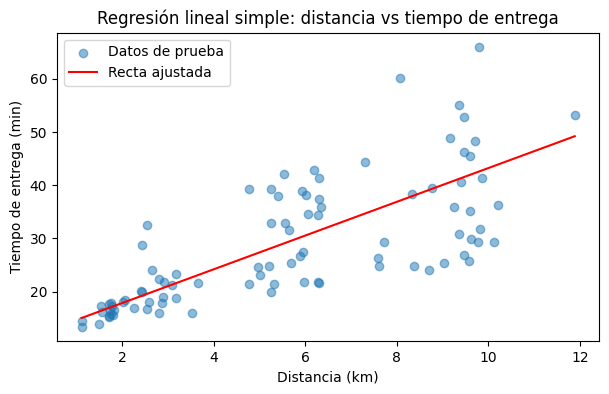

In [32]:
plt.figure(figsize=(7,4))
plt.scatter(X_test, y_test, alpha=0.5, label="Datos de prueba")
xs = np.linspace(X.min().iloc[0], X.max().iloc[0], 100).reshape(-1,1)
plt.plot(xs, modelo.predict(pd.DataFrame(xs, columns=["distancia_km"])), color="red", label="Recta ajustada")
plt.title("Regresión lineal simple: distancia vs tiempo de entrega")
plt.xlabel("Distancia (km)"); plt.ylabel("Tiempo de entrega (min)")
plt.legend(); plt.show()

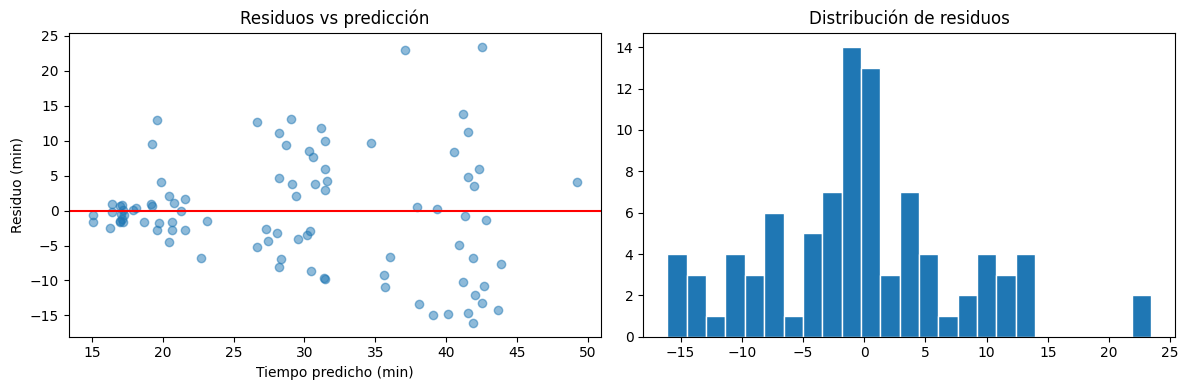

In [33]:
# Revisión de supuestos: residuos
residuos = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].scatter(y_pred, residuos, alpha=0.5); axes[0].axhline(0, color="red")
axes[0].set_title("Residuos vs predicción"); axes[0].set_xlabel("Tiempo predicho (min)"); axes[0].set_ylabel("Residuo (min)")
axes[1].hist(residuos, bins=25, edgecolor="white"); axes[1].set_title("Distribución de residuos")
plt.tight_layout(); plt.show()

**Cómo se obtuvo e interpretación:**
- El modelo se entrenó con el 80 % de las 453 entregas limpias y se evaluó con el 20 % restante (`random_state=42`).
- **Coeficiente = 3.17:** cada kilómetro adicional se asocia, en promedio, con **3.17 minutos más** de entrega.
- **Intercepto = 11.55 min:** es el tiempo base estimado (preparación y salida) antes de recorrer distancia.
- **R² = 0.529:** la distancia explica cerca del **53 %** de la variación del tiempo; el otro 47 % se debe a otros factores (carga de la cocina, ítems, sede).
- **RMSE = 7.97 min:** la predicción se equivoca en unos 8 minutos en promedio. Al prometer un tiempo, habría que dar ese margen.
- Ejemplo: para una entrega de 5 km, el modelo estima 11.55 + 3.17 × 5 ≈ **27.4 min**.

**Límites del modelo:**
- Usa una sola variable: no considera la carga de la cocina, los ítems del pedido ni la sede, que también influyen (las entregas largas en hora de carga alta tardan casi 42 min).
- Muestra asociación, no causalidad.
- Supone una relación lineal y residuos sin patrón; se revisa en el gráfico de residuos.
- Los 12 tiempos atípicos que se conservaron pueden afectar la pendiente; en la entrega final se comparará el modelo con y sin ellos.

## 6. Pendientes, dificultades y siguientes pasos

**Realizado en este checkpoint**
- Carga de las 4 tablas en SQLite, verificación de PK/FK y consultas JOIN con conteos.
- EDA con resúmenes y 4 gráficos interpretados.
- Identificación y cuantificación de nulos, duplicados, espacios, formatos de fecha y valores extremos; primera limpieza y tabla `dataset_limpio`.
- Primer modelo de regresión lineal simple con R², MSE y RMSE.

**Pendiente**
- Decidir el tratamiento final de los atípicos y comparar el modelo con y sin ellos.
- Limpiar las tablas Clientes, Catalogo y Sedes.
- Guardar las predicciones de la regresión en SQLite.
- Segmentación con K-Means (escalado, elección de k con inercia y silueta, perfiles de grupo).
- Redactar el informe técnico final y la recomendación para el negocio.

**Dificultades encontradas**
- Fechas registradas en varios formatos y textos con espacios, que obligaron a estandarizar antes de analizar.
- Decidir qué valores extremos son errores y cuáles son entregas reales.